In [1]:
import sys
import importlib.util
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

print("EXPLAINABLE AI ENVIRONMENT VERIFICATION")
print("-" * 65)

print("Python version:", sys.version.split()[0])
print("Project root:", PROJECT_ROOT)
print("Project exists:", PROJECT_ROOT.exists())

required_packages = [
    "numpy",
    "pandas",
    "sklearn",
    "lightgbm",
    "shap",
    "matplotlib",
    "seaborn",
    "joblib",
    "pyarrow"
]

for package in required_packages:
    available = importlib.util.find_spec(package) is not None

    print(
        f"{package}: "
        f"{'AVAILABLE' if available else 'MISSING'}"
    )

print("-" * 65)
print("Environment verification completed.")

EXPLAINABLE AI ENVIRONMENT VERIFICATION
-----------------------------------------------------------------
Python version: 3.12.10
Project root: C:\Users\pc\XAI-Intrusion-Detection
Project exists: True
numpy: AVAILABLE
pandas: AVAILABLE
sklearn: AVAILABLE
lightgbm: AVAILABLE
shap: AVAILABLE
matplotlib: AVAILABLE
seaborn: AVAILABLE
joblib: AVAILABLE
pyarrow: AVAILABLE
-----------------------------------------------------------------
Environment verification completed.


In [2]:
# Research artifact discovery

from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import shap
import lightgbm
import json

PROJECT_ROOT = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
CONFIG_DIR = PROJECT_ROOT / "config"
PROCESSED_DIR = PROJECT_ROOT / "processed_data"
FIGURES_DIR = PROJECT_ROOT / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

print("EXPLAINABLE AI ARTIFACT DISCOVERY")
print("-" * 65)

print("SHAP version:", shap.__version__)
print("LightGBM version:", lightgbm.__version__)

directories = {
    "MODELS": MODELS_DIR,
    "RESULTS": RESULTS_DIR,
    "CONFIGURATION": CONFIG_DIR,
    "PROCESSED DATA": PROCESSED_DIR
}

for name, directory in directories.items():

    print(f"\n{name}")
    print("-" * 65)

    assert directory.exists(), (
        f"Directory missing: {directory}"
    )

    files = sorted(
        p for p in directory.iterdir()
        if p.is_file()
    )

    for file in files:
        print(
            f"{file.name} | "
            f"{file.stat().st_size / 1024**2:.2f} MB"
        )

    print("Total files:", len(files))

print("-" * 65)
print("Research artifact discovery completed.")

EXPLAINABLE AI ARTIFACT DISCOVERY
-----------------------------------------------------------------
SHAP version: 0.54.1
LightGBM version: 4.7.0

MODELS
-----------------------------------------------------------------
03_dummy_classifier.joblib | 0.00 MB
03_lightgbm.joblib | 5.15 MB
03_logistic_regression.joblib | 0.01 MB
03_random_forest.joblib | 41.29 MB
03_xgboost.joblib | 2.88 MB
Total files: 5

RESULTS
-----------------------------------------------------------------
02_artifact_verification.csv | 0.00 MB
02_class_representation_verification.csv | 0.00 MB
02_class_weight_verification.csv | 0.00 MB
02_class_weights.csv | 0.00 MB
02_class_weights.joblib | 0.00 MB
02_feature_names.json | 0.00 MB
02_feature_scale_analysis.csv | 0.01 MB
02_final_dataset_summary.csv | 0.00 MB
02_final_readiness_checks.csv | 0.00 MB
02_invalid_record_impact.csv | 0.00 MB
02_invalid_value_treatment.csv | 0.00 MB
02_label_encoder.joblib | 0.00 MB
02_label_encoding_mapping.csv | 0.00 MB
02_median_replaceme

In [3]:
# Selected model and test artifact identification

print("SELECTED MODEL CONFIGURATION")
print("-" * 65)

with open(
    CONFIG_DIR / "03_selected_model.json",
    encoding="utf-8"
) as f:
    selected_model_config = json.load(f)

print(json.dumps(selected_model_config, indent=4))

print("\nSAVED MODEL FILES")
print("-" * 65)

for file in sorted(MODELS_DIR.iterdir()):
    if file.is_file():
        print(file.name)

print("\nREQUIRED PREPROCESSING AND TEST ARTIFACTS")
print("-" * 65)

keywords = [
    "indices",
    "scaler",
    "replacement",
    "feature_names",
    "sentinel",
    "encoder",
    "classes",
    "partition"
]

for directory in [RESULTS_DIR, CONFIG_DIR, PROCESSED_DIR]:

    for file in sorted(directory.iterdir()):

        if file.is_file() and any(
            keyword in file.name.lower()
            for keyword in keywords
        ):
            print(f"{directory.name}/{file.name}")

print("-" * 65)
print("Artifact identification completed.")

SELECTED MODEL CONFIGURATION
-----------------------------------------------------------------
{
    "selected_model": "LightGBM",
    "selection_metric": "Macro_F1",
    "validation_macro_f1": 0.8860619232653603,
    "validation_accuracy": 0.9986363456045699,
    "validation_balanced_accuracy": 0.9024556139489198,
    "validation_weighted_f1": 0.9986859905677622,
    "training_time_seconds": 278.3043744000006,
    "prediction_time_seconds": 21.77259159999994,
    "model_path": "models\\03_lightgbm.joblib",
    "number_of_features": 69,
    "number_of_classes": 15,
    "random_state": 42,
    "independent_test_used_for_selection": false
}

SAVED MODEL FILES
-----------------------------------------------------------------
03_dummy_classifier.joblib
03_lightgbm.joblib
03_logistic_regression.joblib
03_random_forest.joblib
03_xgboost.joblib

REQUIRED PREPROCESSING AND TEST ARTIFACTS
-----------------------------------------------------------------
results/02_feature_names.json
results/02_

In [4]:
# Model and preprocessing artifact loading

print("EXPLAINABLE AI ARTIFACT LOADING")
print("-" * 65)

# Locate the trained LightGBM model

model_candidates = [
    path for path in MODELS_DIR.glob("*.joblib")
    if "lightgbm" in path.name.lower()
    or "lgbm" in path.name.lower()
]

assert len(model_candidates) == 1, (
    f"Model candidates: {model_candidates}"
)

model_path = model_candidates[0]

xai_model = joblib.load(model_path)

# Load development-only preprocessing artifacts

xai_scaler = joblib.load(
    RESULTS_DIR / "03_development_scaler.joblib"
)

xai_feature_names = list(joblib.load(
    RESULTS_DIR / "03_development_feature_names.joblib"
))

xai_replacement_values = joblib.load(
    RESULTS_DIR / "03_development_replacement_values.joblib"
)

xai_sentinel_features = joblib.load(
    RESULTS_DIR / "03_development_sentinel_features.joblib"
)

xai_label_encoder = joblib.load(
    RESULTS_DIR / "02_label_encoder.joblib"
)

# Load independent test artifacts

xai_test_indices = np.load(
    RESULTS_DIR / "02_test_indices.npy"
)

xai_test_targets = np.load(
    RESULTS_DIR / "04_independent_targets.npy"
)

xai_test_predictions = np.load(
    RESULTS_DIR / "04_independent_predictions.npy"
)

xai_development_indices = np.load(
    RESULTS_DIR / "03_development_indices.npy"
)

xai_validation_indices = np.load(
    RESULTS_DIR / "03_validation_indices.npy"
)

# Verify artifact integrity

xai_checks = {
    "Correct model type":
        isinstance(xai_model, lightgbm.LGBMClassifier),

    "Expected feature count":
        len(xai_feature_names) == 69,

    "Unique feature names":
        len(set(xai_feature_names)) == 69,

    "Model feature count":
        xai_model.n_features_in_ == 69,

    "Scaler feature order":
        np.array_equal(
            xai_scaler.feature_names_in_,
            xai_feature_names
        ),

    "Development-only scaler":
        bool(np.all(
            xai_scaler.n_samples_seen_ == 1613310
        )),

    "Expected replacement features":
        len(xai_replacement_values) == 10,

    "Sentinel features preserved":
        set(xai_sentinel_features).isdisjoint(
            xai_replacement_values
        ),

    "Expected test records":
        len(xai_test_indices) == 504160,

    "Unique test indices":
        len(np.unique(xai_test_indices)) == 504160,

    "Target and prediction dimensions":
        xai_test_targets.shape ==
        xai_test_predictions.shape ==
        (504160,),

    "Expected model classes":
        len(xai_model.classes_) == 15,

    "Expected encoder classes":
        len(xai_label_encoder.classes_) == 15,

    "No development-test overlap":
        np.intersect1d(
            xai_development_indices,
            xai_test_indices
        ).size == 0,

    "No validation-test overlap":
        np.intersect1d(
            xai_validation_indices,
            xai_test_indices
        ).size == 0
}

xai_checks_df = pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in xai_checks.items()
])

display(xai_checks_df)

assert all(xai_checks.values()), (
    "Artifact integrity verification failed."
)

print("-" * 65)
print("Model file:", model_path.name)
print("Model:", type(xai_model).__name__)
print("Features:", len(xai_feature_names))
print("Classes:", len(xai_model.classes_))
print("Test records:", len(xai_test_indices))
print("Total checks:", len(xai_checks))
print("Passed checks:", sum(xai_checks.values()))
print("Artifact integrity verification: PASS")
print("Explainable AI artifact loading completed.")

EXPLAINABLE AI ARTIFACT LOADING
-----------------------------------------------------------------


,Verification_Check,Status
0,Correct model type,PASS
1,Expected feature count,PASS
2,Unique feature names,PASS
3,Model feature count,PASS
4,Scaler feature order,PASS
5,Development-only scaler,PASS
6,Expected replacement features,PASS
7,Sentinel features preserved,PASS
8,Expected test records,PASS
9,Unique test indices,PASS


-----------------------------------------------------------------
Model file: 03_lightgbm.joblib
Model: LGBMClassifier
Features: 69
Classes: 15
Test records: 504160
Total checks: 15
Passed checks: 15
Artifact integrity verification: PASS
Explainable AI artifact loading completed.


In [5]:
# Stratified SHAP sample preparation

import numpy as np
import pandas as pd

print("SHAP SAMPLE PREPARATION")
print("-" * 65)

xai_random_state = 42
xai_samples_per_class = 200

xai_rng = np.random.default_rng(
    xai_random_state
)

xai_sample_positions = []

for class_id in np.unique(xai_test_targets):

    class_positions = np.flatnonzero(
        xai_test_targets == class_id
    )

    sample_count = min(
        xai_samples_per_class,
        len(class_positions)
    )

    selected_positions = xai_rng.choice(
        class_positions,
        size=sample_count,
        replace=False
    )

    xai_sample_positions.extend(
        selected_positions.tolist()
    )

xai_sample_positions = np.array(
    xai_sample_positions,
    dtype=np.int64
)

xai_rng.shuffle(xai_sample_positions)

# Recover original dataset indices

xai_sample_indices = xai_test_indices[
    xai_sample_positions
]

y_xai_sample = xai_test_targets[
    xai_sample_positions
]

y_xai_reference_predictions = (
    xai_test_predictions[xai_sample_positions]
)

# Sample distribution

xai_sample_distribution = pd.DataFrame({
    "Class": xai_label_encoder.inverse_transform(
        np.unique(y_xai_sample)
    ),
    "Independent_Test_Records": [
        int((xai_test_targets == c).sum())
        for c in np.unique(y_xai_sample)
    ],
    "SHAP_Sample_Records": [
        int((y_xai_sample == c).sum())
        for c in np.unique(y_xai_sample)
    ]
})

display(xai_sample_distribution)

# Verify sample integrity

sample_checks = {
    "All 15 classes represented":
        len(np.unique(y_xai_sample)) == 15,

    "No duplicate sample records":
        len(np.unique(xai_sample_indices))
        == len(xai_sample_indices),

    "Independent test membership":
        bool(np.isin(
            xai_sample_indices,
            xai_test_indices
        ).all()),

    "No development overlap":
        np.intersect1d(
            xai_sample_indices,
            xai_development_indices
        ).size == 0,

    "No validation overlap":
        np.intersect1d(
            xai_sample_indices,
            xai_validation_indices
        ).size == 0,

    "Target and prediction alignment":
        len(y_xai_sample)
        == len(y_xai_reference_predictions)
        == len(xai_sample_indices)
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in sample_checks.items()
]))

assert all(sample_checks.values()), (
    "SHAP sample verification failed."
)

print("-" * 65)
print("Random state:", xai_random_state)
print("Maximum samples per class:",
      xai_samples_per_class)
print("Total SHAP sample records:",
      len(xai_sample_indices))
print("Classes represented:",
      len(np.unique(y_xai_sample)))
print("Verification checks:",
      len(sample_checks))
print("Passed checks:",
      sum(sample_checks.values()))
print("SHAP sample preparation completed.")

SHAP SAMPLE PREPARATION
-----------------------------------------------------------------


,Class,Independent_Test_Records,SHAP_Sample_Records
0,BENIGN,419012,200
1,Bot,390,200
2,DDoS,25603,200
3,DoS GoldenEye,2057,200
4,DoS Hulk,34569,200
5,DoS Slowhttptest,1046,200
6,DoS slowloris,1077,200
7,FTP-Patator,1186,200
8,Heartbleed,2,2
9,Infiltration,7,7


,Verification_Check,Status
0,All 15 classes represented,PASS
1,No duplicate sample records,PASS
2,Independent test membership,PASS
3,No development overlap,PASS
4,No validation overlap,PASS
5,Target and prediction alignment,PASS


-----------------------------------------------------------------
Random state: 42
Maximum samples per class: 200
Total SHAP sample records: 2343
Classes represented: 15
Verification checks: 6
Passed checks: 6
SHAP sample preparation completed.


In [6]:
# SHAP sample feature reconstruction

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import joblib

start_time = perf_counter()

print("SHAP FEATURE RECONSTRUCTION")
print("-" * 65)

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

results_dir = project_root / "results"

feature_names = list(joblib.load(
    results_dir / "03_development_feature_names.joblib"
))

scaler = joblib.load(
    results_dir / "03_development_scaler.joblib"
)

replacement_values = joblib.load(
    results_dir / "03_development_replacement_values.joblib"
)

parquet_file = pq.ParquetFile(
    project_root / "processed_data"
    / "CICIDS2017_cleaned.parquet"
)

assert len(feature_names) == 69
assert list(scaler.feature_names_in_) == feature_names
assert np.all(scaler.n_samples_seen_ == 1613310)

total_records = parquet_file.metadata.num_rows
sample_count = len(xai_sample_indices)

assert total_records == 2520798
assert np.all(xai_sample_indices >= 0)
assert np.all(xai_sample_indices < total_records)
assert len(np.unique(xai_sample_indices)) == sample_count

position_map = np.full(
    total_records, -1, dtype=np.int64
)

position_map[xai_sample_indices] = np.arange(
    sample_count
)

X_xai_sample = np.empty(
    (sample_count, 69),
    dtype=np.float32
)

written = np.zeros(sample_count, dtype=bool)

replacement_counts = {
    feature: 0
    for feature in replacement_values
}

scaler_mean_before = scaler.mean_.copy()
scaler_var_before = scaler.var_.copy()
scaler_scale_before = scaler.scale_.copy()
scaler_samples_before = np.copy(
    scaler.n_samples_seen_
)

source_offset = 0

for batch in parquet_file.iter_batches(
    batch_size=50000,
    columns=feature_names
):

    batch_end = source_offset + batch.num_rows

    local_positions = position_map[
        source_offset:batch_end
    ]

    local_mask = local_positions >= 0

    if local_mask.any():

        destinations = local_positions[local_mask]

        assert not written[destinations].any()

        sample_batch = batch.to_pandas().loc[
            local_mask, feature_names
        ].astype(np.float64)

        for feature, replacement in (
            replacement_values.items()
        ):

            values = sample_batch[feature].to_numpy()

            invalid_mask = (
                ~np.isfinite(values)
                | (values < 0)
            )

            replacement_counts[feature] += int(
                invalid_mask.sum()
            )

            sample_batch.loc[
                invalid_mask, feature
            ] = replacement

        transformed = scaler.transform(
            sample_batch
        ).astype(np.float32)

        X_xai_sample[destinations] = transformed
        written[destinations] = True

    source_offset = batch_end

# Verify reconstruction

reconstruction_checks = {

    "Complete source coverage":
        source_offset == total_records,

    "Complete sample coverage":
        bool(written.all()),

    "Correct feature dimensions":
        X_xai_sample.shape == (2343, 69),

    "Correct data type":
        X_xai_sample.dtype == np.float32,

    "All feature values finite":
        bool(np.isfinite(X_xai_sample).all()),

    "Scaler parameters unchanged":
        bool(
            np.array_equal(
                scaler_mean_before, scaler.mean_
            )
            and np.array_equal(
                scaler_var_before, scaler.var_
            )
            and np.array_equal(
                scaler_scale_before, scaler.scale_
            )
            and np.array_equal(
                scaler_samples_before,
                scaler.n_samples_seen_
            )
        ),

    "Development-only scaler":
        bool(np.all(
            scaler.n_samples_seen_ == 1613310
        ))
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in reconstruction_checks.items()
]))

assert all(reconstruction_checks.values()), (
    "SHAP feature reconstruction failed."
)

X_xai_df = pd.DataFrame(
    X_xai_sample,
    columns=feature_names
)

print("-" * 65)
print("Source records scanned:", source_offset)
print("Sample records reconstructed:", written.sum())
print("Feature shape:", X_xai_sample.shape)
print("Data type:", X_xai_sample.dtype)
print("Replacement counts:", replacement_counts)
print("Passed checks:", sum(reconstruction_checks.values()))
print("Total checks:", len(reconstruction_checks))
print(f"Execution time: {perf_counter() - start_time:.2f} seconds")
print("SHAP feature reconstruction completed.")

SHAP FEATURE RECONSTRUCTION
-----------------------------------------------------------------


,Verification_Check,Status
0,Complete source coverage,PASS
1,Complete sample coverage,PASS
2,Correct feature dimensions,PASS
3,Correct data type,PASS
4,All feature values finite,PASS
5,Scaler parameters unchanged,PASS
6,Development-only scaler,PASS


-----------------------------------------------------------------
Source records scanned: 2520798
Sample records reconstructed: 2343
Feature shape: (2343, 69)
Data type: float32
Replacement counts: {'Flow IAT Min': 2, 'Flow Duration': 0, 'Flow Packets/s': 0, 'Flow IAT Mean': 0, 'Flow IAT Max': 0, 'Flow Bytes/s': 0, 'min_seg_size_forward': 0, 'Fwd Header Length': 0, 'Bwd Header Length': 0, 'Fwd IAT Min': 0}
Passed checks: 7
Total checks: 7
Execution time: 1.90 seconds
SHAP feature reconstruction completed.


In [7]:
# SHAP sample prediction consistency

import numpy as np
import pandas as pd
import joblib

from time import perf_counter

start_time = perf_counter()

print("SHAP SAMPLE PREDICTION CONSISTENCY")
print("-" * 65)

# Load the selected LightGBM model

xai_model = joblib.load(
    project_root / "models" / "03_lightgbm.joblib"
)

# Generate predictions

y_xai_pred = xai_model.predict(
    X_xai_sample
)

# Compare with independent evaluation predictions

prediction_matches = (
    y_xai_pred == y_xai_reference_predictions
)

matching_predictions = int(
    prediction_matches.sum()
)

mismatching_predictions = int(
    (~prediction_matches).sum()
)

prediction_agreement = float(
    prediction_matches.mean()
)

# Verification checks

prediction_checks = {

    "Correct model feature count":
        xai_model.n_features_in_ == 69,

    "Expected model classes":
        len(xai_model.classes_) == 15,

    "Correct prediction dimensions":
        y_xai_pred.shape == y_xai_sample.shape,

    "Reference prediction dimensions":
        y_xai_pred.shape
        == y_xai_reference_predictions.shape,

    "Complete prediction agreement":
        np.array_equal(
            y_xai_pred,
            y_xai_reference_predictions
        ),

    "No prediction mismatches":
        mismatching_predictions == 0
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in prediction_checks.items()
]))

print("-" * 65)

print("Model:", type(xai_model).__name__)
print("Sample records:", len(X_xai_sample))
print("Predictions generated:", len(y_xai_pred))
print("Matching predictions:", matching_predictions)
print("Mismatching predictions:", mismatching_predictions)

print(
    f"Prediction agreement: "
    f"{prediction_agreement * 100:.4f}%"
)

print("Total checks:", len(prediction_checks))
print("Passed checks:", sum(prediction_checks.values()))

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

assert all(prediction_checks.values()), (
    "SHAP prediction consistency verification failed."
)

print("-" * 65)
print("SHAP prediction consistency verification: PASS")
print("SHAP sample ready for explainability analysis.")

SHAP SAMPLE PREDICTION CONSISTENCY
-----------------------------------------------------------------


,Verification_Check,Status
0,Correct model feature count,PASS
1,Expected model classes,PASS
2,Correct prediction dimensions,PASS
3,Reference prediction dimensions,PASS
4,Complete prediction agreement,PASS
5,No prediction mismatches,PASS


-----------------------------------------------------------------
Model: LGBMClassifier
Sample records: 2343
Predictions generated: 2343
Matching predictions: 2343
Mismatching predictions: 0
Prediction agreement: 100.0000%
Total checks: 6
Passed checks: 6
Execution time: 0.30 seconds
-----------------------------------------------------------------
SHAP prediction consistency verification: PASS
SHAP sample ready for explainability analysis.


In [8]:
# SHAP TreeExplainer initialization

import shap
import numpy as np
import pandas as pd

from time import perf_counter

start_time = perf_counter()

assert all(prediction_checks.values())
assert all(reconstruction_checks.values())

print("SHAP TREE EXPLAINER INITIALIZATION")
print("-" * 65)

# Initialize the explainer

xai_explainer = shap.TreeExplainer(
    xai_model,
    feature_perturbation="tree_path_dependent",
    model_output="raw"
)

# Extract baseline values

xai_expected_values = np.asarray(
    xai_explainer.expected_value,
    dtype=np.float64
).reshape(-1)

# Recover class names in model output order

xai_class_names = xai_label_encoder.inverse_transform(
    xai_model.classes_.astype(int)
)

# Verify explainer configuration

explainer_checks = {

    "TreeExplainer initialized":
        isinstance(
            xai_explainer,
            shap.TreeExplainer
        ),

    "Expected feature count":
        X_xai_sample.shape[1] == 69,

    "Expected class count":
        len(xai_class_names) == 15,

    "Expected baseline count":
        len(xai_expected_values) == 15,

    "Finite baseline values":
        bool(np.isfinite(
            xai_expected_values
        ).all()),

    "Prediction consistency verified":
        bool(all(prediction_checks.values()))
}

# Display class baseline values

xai_baseline_df = pd.DataFrame({

    "Class_ID": xai_model.classes_,

    "Class_Name": xai_class_names,

    "Expected_Value": xai_expected_values

})

print("\nSHAP BASELINE VALUES")
print("-" * 65)

display(xai_baseline_df)

print("\nEXPLAINER VERIFICATION")
print("-" * 65)

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in explainer_checks.items()
]))

print("-" * 65)
print("SHAP version:", shap.__version__)
print("Model:", type(xai_model).__name__)
print("Explainer:", type(xai_explainer).__name__)
print("Feature perturbation: tree_path_dependent")
print("Model output: raw")
print("Sample records:", len(X_xai_sample))
print("Features:", X_xai_sample.shape[1])
print("Classes:", len(xai_class_names))
print("Baseline values:", len(xai_expected_values))
print("Total checks:", len(explainer_checks))
print("Passed checks:", sum(explainer_checks.values()))

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

assert all(explainer_checks.values()), (
    "SHAP explainer initialization failed."
)

print("-" * 65)
print("SHAP TreeExplainer initialized successfully.")

SHAP TREE EXPLAINER INITIALIZATION
-----------------------------------------------------------------

SHAP BASELINE VALUES
-----------------------------------------------------------------


,Class_ID,Class_Name,Expected_Value
0,0,BENIGN,3.302685
1,1,Bot,-11.686390
2,2,DDoS,-9.912874
3,3,DoS GoldenEye,-10.515058
4,4,DoS Hulk,-8.536096
5,5,DoS Slowhttptest,-10.089414
6,6,DoS slowloris,-9.438728
7,7,FTP-Patator,-12.040540
8,8,Heartbleed,-12.085500
9,9,Infiltration,-12.060092



EXPLAINER VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Status
0,TreeExplainer initialized,PASS
1,Expected feature count,PASS
2,Expected class count,PASS
3,Expected baseline count,PASS
4,Finite baseline values,PASS
5,Prediction consistency verified,PASS


-----------------------------------------------------------------
SHAP version: 0.54.1
Model: LGBMClassifier
Explainer: TreeExplainer
Feature perturbation: tree_path_dependent
Model output: raw
Sample records: 2343
Features: 69
Classes: 15
Baseline values: 15
Total checks: 6
Passed checks: 6
Execution time: 3.97 seconds
-----------------------------------------------------------------
SHAP TreeExplainer initialized successfully.


In [9]:
# Multiclass SHAP value computation

import shap
import numpy as np
import pandas as pd

from time import perf_counter

assert all(explainer_checks.values())

start_time = perf_counter()

print("MULTICLASS SHAP VALUE COMPUTATION")
print("-" * 65)

# Calculate SHAP values

print("Calculating SHAP values...", flush=True)

raw_shap_values = xai_explainer.shap_values(
    X_xai_sample,
    check_additivity=False
)

# Standardize SHAP output dimensions

if isinstance(raw_shap_values, list):

    xai_shap_values = np.stack(
        raw_shap_values,
        axis=-1
    )

else:

    xai_shap_values = np.asarray(
        raw_shap_values
    )

# Expected dimensions

expected_shap_shape = (
    len(X_xai_sample),
    len(feature_names),
    len(xai_class_names)
)

# Verify SHAP values

shap_value_checks = {

    "SHAP values generated":
        xai_shap_values.size > 0,

    "Correct SHAP dimensions":
        xai_shap_values.shape
        == expected_shap_shape,

    "All SHAP values finite":
        bool(np.isfinite(
            xai_shap_values
        ).all()),

    "Non-zero feature contributions":
        bool(np.any(
            xai_shap_values != 0
        )),

    "Expected sample count":
        xai_shap_values.shape[0] == 2343,

    "Expected feature count":
        xai_shap_values.shape[1] == 69,

    "Expected class count":
        xai_shap_values.shape[2] == 15
}

display(pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in shap_value_checks.items()
]))

print("-" * 65)

print("SHAP dimensions:", xai_shap_values.shape)
print("Data type:", xai_shap_values.dtype)
print("Total SHAP values:", xai_shap_values.size)

print(
    "Minimum SHAP value:",
    float(xai_shap_values.min())
)

print(
    "Maximum SHAP value:",
    float(xai_shap_values.max())
)

print(
    "Mean absolute SHAP value:",
    float(np.abs(xai_shap_values).mean())
)

print(
    f"Memory usage: "
    f"{xai_shap_values.nbytes / 1024**2:.2f} MB"
)

print("Total checks:", len(shap_value_checks))
print("Passed checks:", sum(shap_value_checks.values()))

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

assert all(shap_value_checks.values()), (
    "SHAP value computation verification failed."
)

print("-" * 65)
print("SHAP value computation completed successfully.")

MULTICLASS SHAP VALUE COMPUTATION
-----------------------------------------------------------------
Calculating SHAP values...


,Verification_Check,Status
0,SHAP values generated,PASS
1,Correct SHAP dimensions,PASS
2,All SHAP values finite,PASS
3,Non-zero feature contributions,PASS
4,Expected sample count,PASS
5,Expected feature count,PASS
6,Expected class count,PASS


-----------------------------------------------------------------
SHAP dimensions: (2343, 69, 15)
Data type: float64
Total SHAP values: 2425005
Minimum SHAP value: -4.021895855703411
Maximum SHAP value: 15.875705002567928
Mean absolute SHAP value: 0.06220619212601738
Memory usage: 18.50 MB
Total checks: 7
Passed checks: 7
Execution time: 9.23 seconds
-----------------------------------------------------------------
SHAP value computation completed successfully.


In [10]:
# SHAP additivity verification

import numpy as np
import pandas as pd

from time import perf_counter

assert all(shap_value_checks.values())

start_time = perf_counter()

print("SHAP ADDITIVITY VERIFICATION")
print("-" * 65)

# Recover the underlying LightGBM model

shap_booster = xai_explainer.model.original_model

# Generate original raw prediction scores

xai_raw_scores = shap_booster.predict(
    X_xai_sample,
    raw_score=True
)

xai_raw_scores = np.asarray(xai_raw_scores)

# Extract baseline values

xai_baseline_values = np.asarray(
    xai_explainer.expected_value,
    dtype=np.float64
).reshape(-1)

# Reconstruct raw scores from SHAP contributions

xai_reconstructed_scores = (
    xai_shap_values.sum(axis=1)
    + xai_baseline_values
)

assert xai_raw_scores.shape == (2343, 15)
assert xai_reconstructed_scores.shape == (2343, 15)

# Calculate reconstruction errors

xai_additivity_errors = np.abs(
    xai_raw_scores - xai_reconstructed_scores
)

maximum_additivity_error = float(
    xai_additivity_errors.max()
)

mean_additivity_error = float(
    xai_additivity_errors.mean()
)

# Numerical tolerance

additivity_tolerance = 1e-5

# Compare predicted class positions

original_class_positions = np.argmax(
    xai_raw_scores,
    axis=1
)

reconstructed_class_positions = np.argmax(
    xai_reconstructed_scores,
    axis=1
)

# Verification checks

additivity_checks = {

    "Correct raw score dimensions":
        xai_raw_scores.shape == (2343, 15),

    "Correct reconstructed dimensions":
        xai_reconstructed_scores.shape == (2343, 15),

    "Expected baseline count":
        len(xai_baseline_values) == 15,

    "All raw scores finite":
        bool(np.isfinite(xai_raw_scores).all()),

    "All reconstructed scores finite":
        bool(np.isfinite(
            xai_reconstructed_scores
        ).all()),

    "Maximum error within tolerance":
        maximum_additivity_error <= additivity_tolerance,

    "Complete class prediction agreement":
        bool(np.array_equal(
            original_class_positions,
            reconstructed_class_positions
        ))
}

additivity_checks_df = pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in additivity_checks.items()
])

display(additivity_checks_df)

# Class-specific reconstruction errors

class_additivity_df = pd.DataFrame({

    "Class": xai_class_names,

    "Mean_Absolute_Error":
        xai_additivity_errors.mean(axis=0),

    "Maximum_Absolute_Error":
        xai_additivity_errors.max(axis=0)
})

print("\nCLASS-SPECIFIC ADDITIVITY ERRORS")
print("-" * 65)

display(class_additivity_df)

print("\nADDITIVITY VERIFICATION SUMMARY")
print("-" * 65)

print("Raw score dimensions:", xai_raw_scores.shape)

print(
    "Reconstructed dimensions:",
    xai_reconstructed_scores.shape
)

print("Total scores verified:", xai_raw_scores.size)

print("Baseline values:", len(xai_baseline_values))

print(
    f"Maximum absolute error: "
    f"{maximum_additivity_error:.12e}"
)

print(
    f"Mean absolute error: "
    f"{mean_additivity_error:.12e}"
)

print("Numerical tolerance:", additivity_tolerance)

print(
    "Class prediction agreement:",
    np.array_equal(
        original_class_positions,
        reconstructed_class_positions
    )
)

print("Total checks:", len(additivity_checks))

print("Passed checks:", sum(additivity_checks.values()))

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

xai_additivity_passed = bool(
    all(additivity_checks.values())
)

assert xai_additivity_passed, (
    "SHAP additivity verification failed."
)

print("-" * 65)
print("SHAP additivity verification: PASS")
print("SHAP numerical fidelity verified successfully.")

SHAP ADDITIVITY VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Status
0,Correct raw score dimensions,PASS
1,Correct reconstructed dimensions,PASS
2,Expected baseline count,PASS
3,All raw scores finite,PASS
4,All reconstructed scores finite,PASS
5,Maximum error within tolerance,PASS
6,Complete class prediction agreement,PASS



CLASS-SPECIFIC ADDITIVITY ERRORS
-----------------------------------------------------------------


,Class,Mean_Absolute_Error,Maximum_Absolute_Error
0,BENIGN,3.848039e-15,1.509903e-14
1,Bot,4.685966e-15,2.753353e-14
2,DDoS,4.563713e-15,1.776357e-14
3,DoS GoldenEye,3.814016e-15,1.865175e-14
4,DoS Hulk,4.254072e-15,1.598721e-14
5,DoS Slowhttptest,2.742057e-15,1.154632e-14
6,DoS slowloris,4.221217e-15,1.687539e-14
7,FTP-Patator,9.215372e-15,4.618528e-14
8,Heartbleed,3.658476e-15,1.154632e-14
9,Infiltration,3.315459e-15,1.953993e-14



ADDITIVITY VERIFICATION SUMMARY
-----------------------------------------------------------------
Raw score dimensions: (2343, 15)
Reconstructed dimensions: (2343, 15)
Total scores verified: 35145
Baseline values: 15
Maximum absolute error: 4.973799150321e-14
Mean absolute error: 4.160077214264e-15
Numerical tolerance: 1e-05
Class prediction agreement: True
Total checks: 7
Passed checks: 7
Execution time: 0.16 seconds
-----------------------------------------------------------------
SHAP additivity verification: PASS
SHAP numerical fidelity verified successfully.


GLOBAL SHAP FEATURE IMPORTANCE
-----------------------------------------------------------------


,Rank,Feature,Mean_Absolute_SHAP,Relative_Importance_Percent
0,1,Destination Port,0.554013,12.907354
1,2,Init_Win_bytes_backward,0.432006,10.064848
2,3,Init_Win_bytes_forward,0.318306,7.415863
3,4,min_seg_size_forward,0.287756,6.704110
4,5,Fwd IAT Min,0.166443,3.877785
5,6,Bwd Packets/s,0.161180,3.755151
6,7,Flow Duration,0.142759,3.325999
7,8,Fwd IAT Total,0.141821,3.304138
8,9,Fwd IAT Std,0.114849,2.675740
9,10,Flow IAT Min,0.110244,2.568457


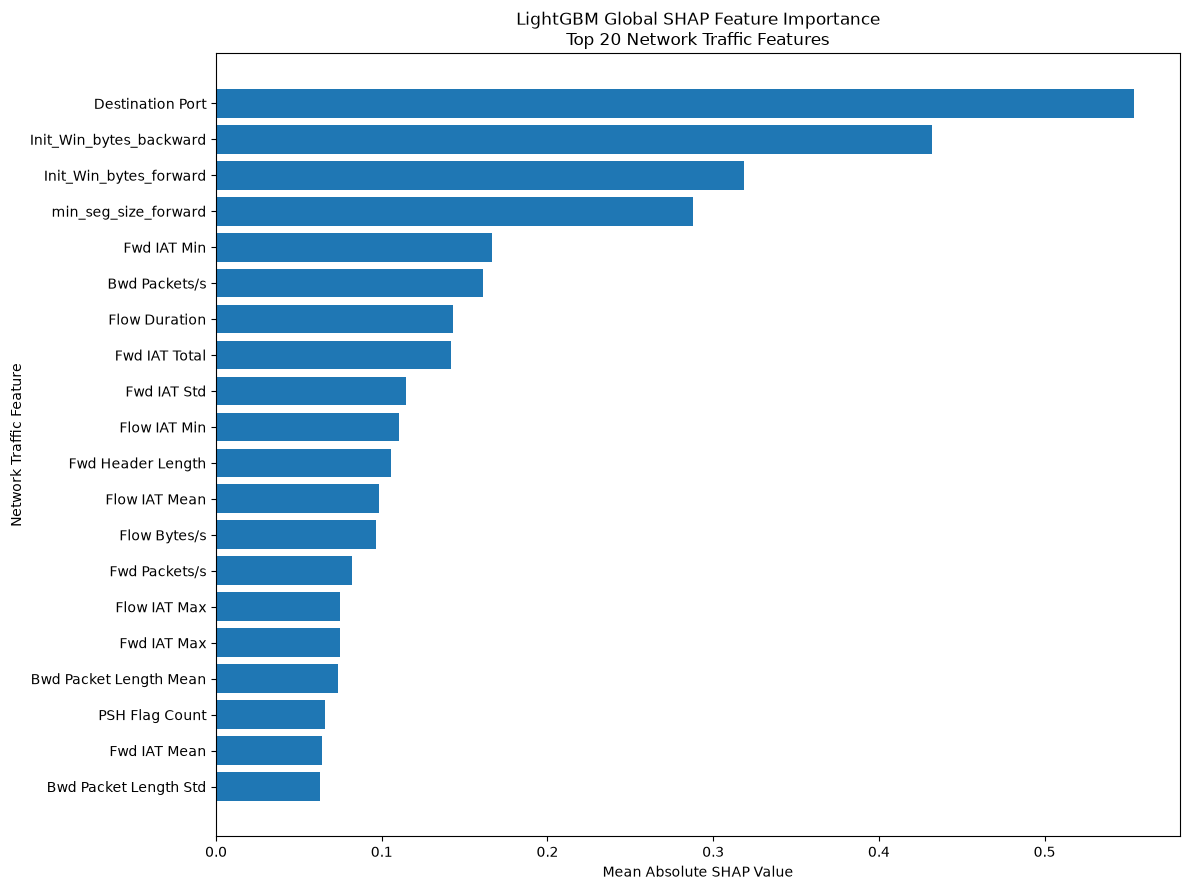


GLOBAL IMPORTANCE VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Status
0,Expected feature count,PASS
1,Unique feature names,PASS
2,All importance values finite,PASS
3,Non-negative importance values,PASS
4,Positive total importance,PASS
5,Correct descending ranking,PASS
6,Relative importance totals 100 percent,PASS
7,Results file saved,PASS
8,Figure saved,PASS



GLOBAL IMPORTANCE SUMMARY
-----------------------------------------------------------------
Features ranked: 69
Most influential feature: Destination Port
Top 10 relative importance: 56.5994 %
Total checks: 9
Passed checks: 9
Execution time: 2.21 seconds
-----------------------------------------------------------------
Global SHAP feature importance: PASS
Global explainability analysis completed.


In [11]:
# Global SHAP feature importance analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from time import perf_counter

assert xai_additivity_passed

start_time = perf_counter()

project_dir = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

figures_dir = project_dir / "figures"
results_dir = project_dir / "results"

figures_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)

# Recover verified feature names

import joblib

global_feature_names = list(
    joblib.load(
        results_dir
        / "03_development_feature_names.joblib"
    )
)

assert len(global_feature_names) == 69

# Calculate mean absolute SHAP importance
# Across samples and class outputs

global_shap_importance = np.abs(
    xai_shap_values
).mean(axis=(0, 2))

global_importance_df = pd.DataFrame({

    "Feature": global_feature_names,

    "Mean_Absolute_SHAP":
        global_shap_importance

}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

# Calculate relative contribution

global_importance_df[
    "Relative_Importance_Percent"
] = (
    global_importance_df["Mean_Absolute_SHAP"]
    / global_importance_df["Mean_Absolute_SHAP"].sum()
    * 100
)

global_importance_df.insert(
    0,
    "Rank",
    np.arange(1, 70)
)

print("GLOBAL SHAP FEATURE IMPORTANCE")
print("-" * 65)

display(global_importance_df.head(20))

# Visualise the top 20 features

top_features = (
    global_importance_df.head(20)
    .sort_values("Mean_Absolute_SHAP")
)

plt.figure(figsize=(12, 9))

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Network Traffic Feature")

plt.title(
    "LightGBM Global SHAP Feature Importance\n"
    "Top 20 Network Traffic Features"
)

plt.tight_layout()

global_figure_path = (
    figures_dir
    / "05_global_shap_feature_importance.png"
)

plt.savefig(
    global_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Save complete feature rankings

global_results_path = (
    results_dir
    / "05_global_shap_feature_importance.csv"
)

global_importance_df.to_csv(
    global_results_path,
    index=False
)

# Verification checks

global_importance_checks = {

    "Expected feature count":
        len(global_importance_df) == 69,

    "Unique feature names":
        global_importance_df["Feature"].nunique() == 69,

    "All importance values finite":
        bool(np.isfinite(
            global_shap_importance
        ).all()),

    "Non-negative importance values":
        bool((global_shap_importance >= 0).all()),

    "Positive total importance":
        global_shap_importance.sum() > 0,

    "Correct descending ranking":
        global_importance_df[
            "Mean_Absolute_SHAP"
        ].is_monotonic_decreasing,

    "Relative importance totals 100 percent":
        bool(np.isclose(
            global_importance_df[
                "Relative_Importance_Percent"
            ].sum(),
            100
        )),

    "Results file saved":
        global_results_path.exists(),

    "Figure saved":
        global_figure_path.exists()
}

global_importance_checks_df = pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed
    in global_importance_checks.items()
])

print("\nGLOBAL IMPORTANCE VERIFICATION")
print("-" * 65)

display(global_importance_checks_df)

global_importance_passed = bool(
    all(global_importance_checks.values())
)

print("\nGLOBAL IMPORTANCE SUMMARY")
print("-" * 65)

print("Features ranked:", len(global_importance_df))

print(
    "Most influential feature:",
    global_importance_df.iloc[0]["Feature"]
)

print(
    "Top 10 relative importance:",
    round(
        global_importance_df.head(10)[
            "Relative_Importance_Percent"
        ].sum(),
        4
    ),
    "%"
)

print("Total checks:", len(global_importance_checks))

print(
    "Passed checks:",
    sum(global_importance_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

assert global_importance_passed

print("-" * 65)
print("Global SHAP feature importance: PASS")
print("Global explainability analysis completed.")

CLASS-SPECIFIC SHAP FEATURE IMPORTANCE
-----------------------------------------------------------------

MOST INFLUENTIAL FEATURE PER CLASS
-----------------------------------------------------------------


,Class,Rank,Feature,Mean_Absolute_SHAP,Relative_Importance_Percent
0,BENIGN,1,Destination Port,1.890558,17.765663
1,Bot,1,Destination Port,1.081694,36.686661
2,DDoS,1,min_seg_size_forward,1.377733,25.984891
3,DoS GoldenEye,1,Init_Win_bytes_backward,1.027041,20.415058
4,DoS Hulk,1,Init_Win_bytes_forward,1.352789,17.277481
5,DoS Slowhttptest,1,min_seg_size_forward,0.740405,12.669873
6,DoS slowloris,1,min_seg_size_forward,0.558027,8.670864
7,FTP-Patator,1,Destination Port,1.371619,72.229734
8,Heartbleed,1,Bwd IAT Total,0.007887,13.395506
9,Infiltration,1,Total Backward Packets,0.153857,20.512445



TOP 10 FEATURES PER CLASS
-----------------------------------------------------------------


,Class,Rank,Feature,Mean_Absolute_SHAP,Relative_Importance_Percent
0,BENIGN,1,Destination Port,1.890558,17.765663
1,BENIGN,2,Init_Win_bytes_forward,1.338637,12.579233
2,BENIGN,3,Init_Win_bytes_backward,1.077321,10.123630
3,BENIGN,4,min_seg_size_forward,0.704381,6.619104
4,BENIGN,5,Bwd Packet Length Std,0.690874,6.492171
...,...,...,...,...,...
971,Web Attack - XSS,6,Flow Duration,0.264064,7.676584
972,Web Attack - XSS,7,Flow IAT Min,0.263091,7.648285
973,Web Attack - XSS,8,Destination Port,0.144713,4.206953
974,Web Attack - XSS,9,Fwd IAT Total,0.144137,4.190196


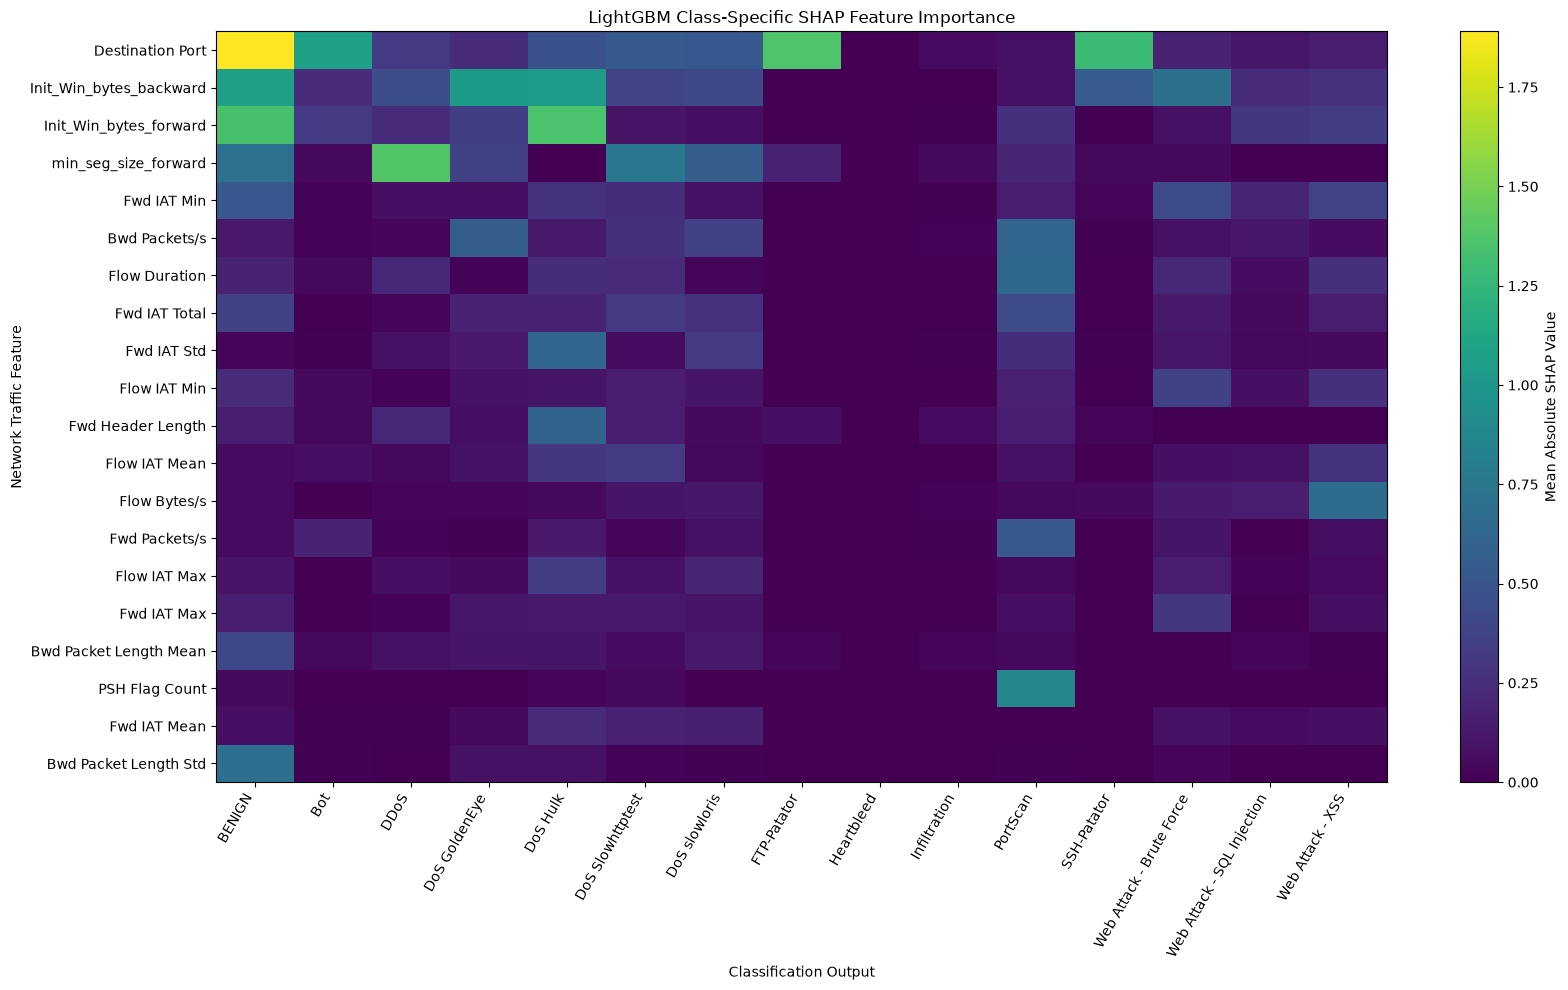


CLASS-SPECIFIC IMPORTANCE VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Status
0,Correct importance dimensions,PASS
1,All 15 classes represented,PASS
2,Complete feature rankings,PASS
3,All importance values finite,PASS
4,Non-negative importance values,PASS
5,All classes have positive importance,PASS
6,Complete top 10 rankings,PASS
7,One leading feature per class,PASS
8,Relative importance totals verified,PASS
9,All results files saved,PASS



CLASS-SPECIFIC IMPORTANCE SUMMARY
-----------------------------------------------------------------
Classes analysed: 15
Features per class: 69
Total feature rankings: 1035
Top 10 feature records: 150
Results files saved: 3
Figures saved: 1
Total checks: 11
Passed checks: 11
Execution time: 4.96 seconds
-----------------------------------------------------------------
Class-specific SHAP importance: PASS
Class-specific explainability analysis completed.


In [12]:
# Class-specific SHAP feature importance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from time import perf_counter

assert global_importance_passed

start_time = perf_counter()

print("CLASS-SPECIFIC SHAP FEATURE IMPORTANCE")
print("-" * 65)

# Calculate feature importance for each class output

class_shap_importance = np.abs(
    xai_shap_values
).mean(axis=0)

assert class_shap_importance.shape == (69, 15)

# Construct complete importance matrix

class_importance_matrix = pd.DataFrame(
    class_shap_importance,
    index=global_feature_names,
    columns=xai_class_names
)

class_importance_matrix.index.name = "Feature"

# Rank features independently for each class

class_importance_records = []

for class_index, class_name in enumerate(
    xai_class_names
):

    importance_values = class_shap_importance[
        :, class_index
    ]

    ranked_indices = np.argsort(
        -importance_values
    )

    total_importance = importance_values.sum()

    for rank, feature_index in enumerate(
        ranked_indices,
        start=1
    ):

        importance = float(
            importance_values[feature_index]
        )

        class_importance_records.append({

            "Class": class_name,

            "Rank": rank,

            "Feature":
                global_feature_names[feature_index],

            "Mean_Absolute_SHAP": importance,

            "Relative_Importance_Percent":
                importance / total_importance * 100
                if total_importance > 0 else 0

        })

class_importance_df = pd.DataFrame(
    class_importance_records
)

# Extract most influential feature per class

class_top_features_df = (
    class_importance_df[
        class_importance_df["Rank"] == 1
    ].reset_index(drop=True)
)

print("\nMOST INFLUENTIAL FEATURE PER CLASS")
print("-" * 65)

display(class_top_features_df)

# Extract top 10 features for every class

class_top10_df = class_importance_df[
    class_importance_df["Rank"] <= 10
].copy()

print("\nTOP 10 FEATURES PER CLASS")
print("-" * 65)

display(class_top10_df)

# Visualise class-specific importance
# Using the globally ranked top 20 features

heatmap_features = (
    global_importance_df.head(20)["Feature"].tolist()
)

heatmap_data = class_importance_matrix.loc[
    heatmap_features
]

fig, ax = plt.subplots(figsize=(17, 10))

image = ax.imshow(
    heatmap_data.to_numpy(),
    aspect="auto",
    cmap="viridis"
)

ax.set_xticks(
    np.arange(len(xai_class_names))
)

ax.set_xticklabels(
    xai_class_names,
    rotation=60,
    ha="right"
)

ax.set_yticks(
    np.arange(len(heatmap_features))
)

ax.set_yticklabels(heatmap_features)

ax.set_xlabel("Classification Output")
ax.set_ylabel("Network Traffic Feature")

ax.set_title(
    "LightGBM Class-Specific SHAP Feature Importance"
)

fig.colorbar(
    image,
    ax=ax,
    label="Mean Absolute SHAP Value"
)

plt.tight_layout()

class_figure_path = (
    figures_dir
    / "05_class_specific_shap_heatmap.png"
)

plt.savefig(
    class_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Save research artifacts

class_matrix_path = (
    results_dir
    / "05_class_shap_importance_matrix.csv"
)

class_ranking_path = (
    results_dir
    / "05_class_shap_feature_rankings.csv"
)

class_top10_path = (
    results_dir
    / "05_class_shap_top10_features.csv"
)

class_importance_matrix.to_csv(
    class_matrix_path
)

class_importance_df.to_csv(
    class_ranking_path,
    index=False
)

class_top10_df.to_csv(
    class_top10_path,
    index=False
)

# Verification checks

class_importance_checks = {

    "Correct importance dimensions":
        class_shap_importance.shape == (69, 15),

    "All 15 classes represented":
        class_importance_df["Class"].nunique() == 15,

    "Complete feature rankings":
        len(class_importance_df) == 1035,

    "All importance values finite":
        bool(np.isfinite(
            class_shap_importance
        ).all()),

    "Non-negative importance values":
        bool((class_shap_importance >= 0).all()),

    "All classes have positive importance":
        bool(
            (class_shap_importance.sum(axis=0) > 0).all()
        ),

    "Complete top 10 rankings":
        len(class_top10_df) == 150,

    "One leading feature per class":
        len(class_top_features_df) == 15,

    "Relative importance totals verified":
        bool(np.allclose(
            class_importance_df.groupby("Class")[
                "Relative_Importance_Percent"
            ].sum().to_numpy(),
            100
        )),

    "All results files saved":
        all(path.exists() for path in [
            class_matrix_path,
            class_ranking_path,
            class_top10_path
        ]),

    "Heatmap saved":
        class_figure_path.exists()
}

class_importance_checks_df = pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed
    in class_importance_checks.items()

])

print("\nCLASS-SPECIFIC IMPORTANCE VERIFICATION")
print("-" * 65)

display(class_importance_checks_df)

class_importance_passed = bool(
    all(class_importance_checks.values())
)

print("\nCLASS-SPECIFIC IMPORTANCE SUMMARY")
print("-" * 65)

print("Classes analysed:", len(xai_class_names))
print("Features per class:", len(global_feature_names))
print("Total feature rankings:", len(class_importance_df))
print("Top 10 feature records:", len(class_top10_df))
print("Results files saved: 3")
print("Figures saved: 1")

print("Total checks:", len(class_importance_checks))

print(
    "Passed checks:",
    sum(class_importance_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

assert class_importance_passed

print("-" * 65)
print("Class-specific SHAP importance: PASS")
print("Class-specific explainability analysis completed.")

LOCAL SHAP PREDICTION EXPLANATIONS
-----------------------------------------------------------------


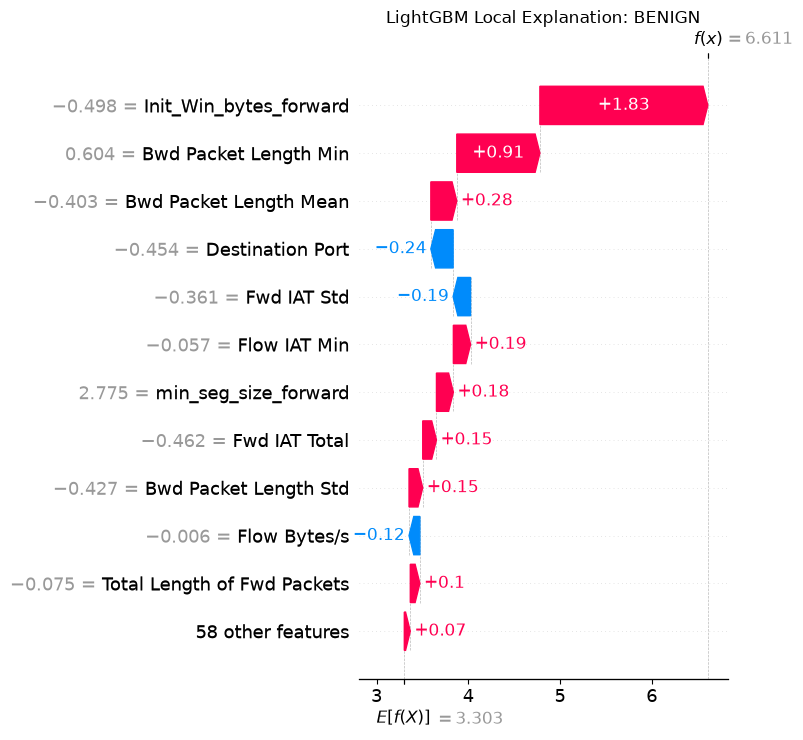

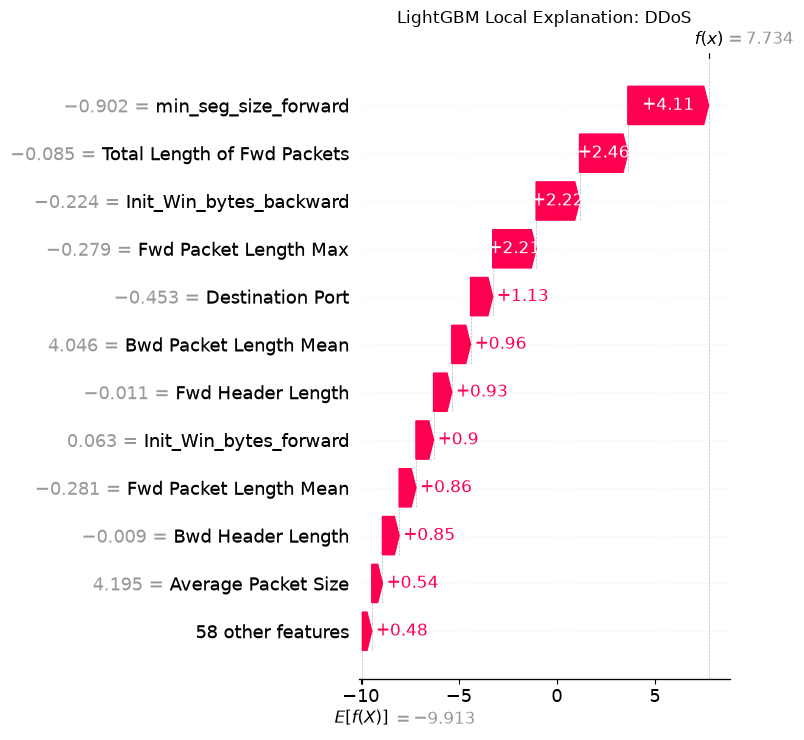

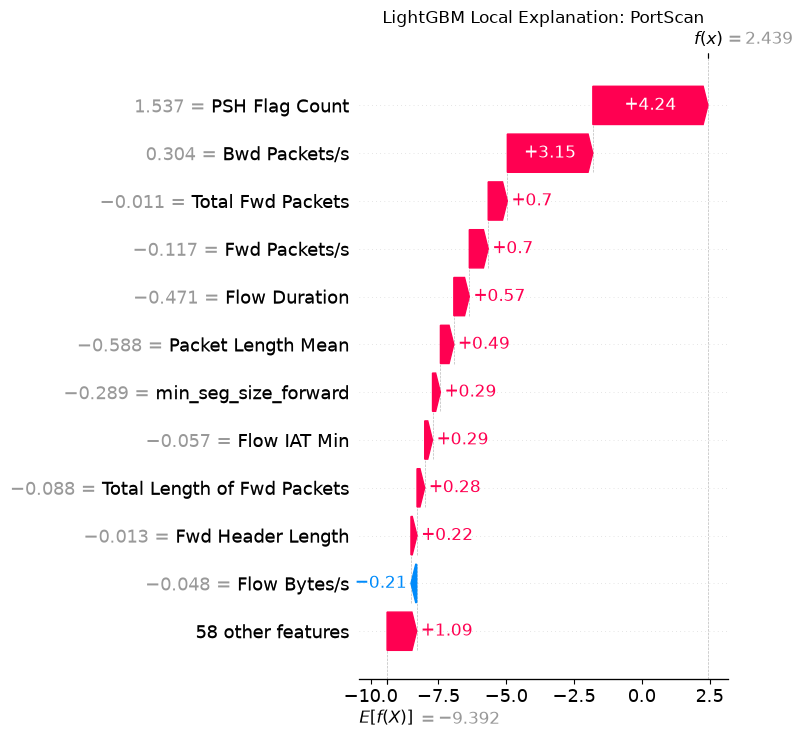

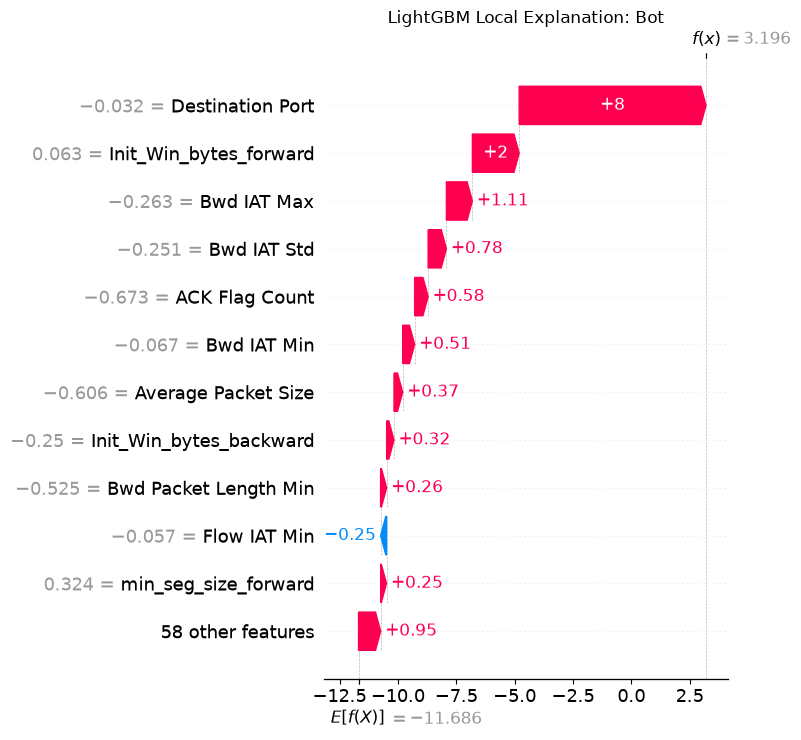

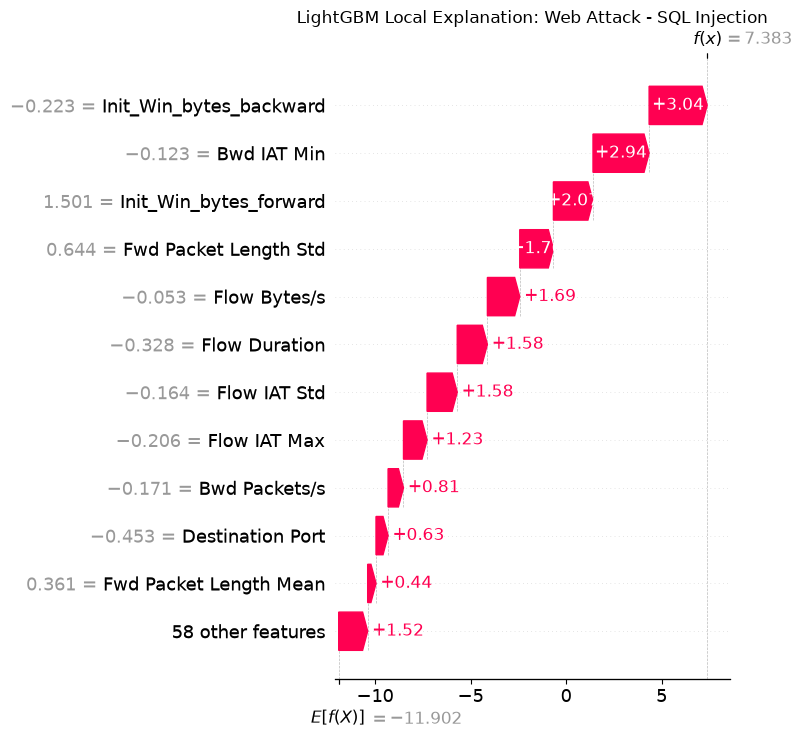


LOCAL EXPLANATION SUMMARY
-----------------------------------------------------------------


,Case,Sample_Position,Predicted_Class,Baseline_Value,Original_Raw_Score,Reconstructed_Raw_Score,Reconstruction_Error,Most_Influential_Feature
0,1,15,BENIGN,3.302685,6.611421,6.611421,4.440892e-15,Init_Win_bytes_forward
1,2,4,DDoS,-9.912874,7.734450,7.734450,7.105427e-15,min_seg_size_forward
2,3,27,PortScan,-9.392198,2.438678,2.438678,3.552714e-15,PSH Flag Count
3,4,6,Bot,-11.686390,3.196328,3.196328,1.332268e-15,Destination Port
4,5,445,Web Attack - SQL Injection,-11.902301,7.383467,7.383467,1.065814e-14,Init_Win_bytes_backward



LOCAL EXPLANATION VERIFICATION
-----------------------------------------------------------------


,Verification_Check,Status
0,Five local cases explained,PASS
1,Five distinct predicted classes,PASS
2,Unique sample positions,PASS
3,Complete feature contributions,PASS
4,All SHAP contributions finite,PASS
5,Numerical reconstruction verified,PASS
6,Five waterfall plots saved,PASS
7,Detailed results saved,PASS
8,Summary results saved,PASS



LOCAL EXPLAINABILITY SUMMARY
-----------------------------------------------------------------
Local cases explained: 5
Features per explanation: 69
Total feature contributions: 345
Waterfall plots saved: 5
Results files saved: 2
Total checks: 9
Passed checks: 9
Execution time: 13.41 seconds
-----------------------------------------------------------------
Local SHAP explanation verification: PASS
Local explainability analysis completed.


In [13]:
# Local SHAP prediction explanations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from time import perf_counter

assert class_importance_passed
assert xai_additivity_passed

start_time = perf_counter()

print("LOCAL SHAP PREDICTION EXPLANATIONS")
print("-" * 65)

# Prepare sample feature matrix

local_features = np.asarray(X_xai_sample)

assert local_features.shape == (2343, 69)

# Recover model predictions

local_predictions = np.argmax(
    xai_raw_scores,
    axis=1
)

local_baselines = np.asarray(
    xai_explainer.expected_value
).reshape(-1)

# Select representative predicted classes

local_cases = [
    "BENIGN",
    "DDoS",
    "PortScan",
    "Bot",
    "Web Attack - SQL Injection"
]

local_explanation_records = []
local_summary_records = []
local_figure_paths = []

# Generate individual explanations

for case_number, class_name in enumerate(
    local_cases,
    start=1
):

    class_index = list(
        xai_class_names
    ).index(class_name)

    candidate_positions = np.flatnonzero(
        local_predictions == class_index
    )

    assert len(candidate_positions) > 0, (
        f"No predictions available for {class_name}"
    )

    # Select first available predicted record

    sample_position = int(
        candidate_positions[0]
    )

    feature_values = local_features[
        sample_position
    ]

    shap_contributions = xai_shap_values[
        sample_position,
        :,
        class_index
    ]

    baseline_value = float(
        local_baselines[class_index]
    )

    reconstructed_score = float(
        baseline_value + shap_contributions.sum()
    )

    original_score = float(
        xai_raw_scores[
            sample_position,
            class_index
        ]
    )

    reconstruction_error = abs(
        reconstructed_score - original_score
    )

    # Construct SHAP explanation

    local_explanation = shap.Explanation(

        values=shap_contributions,

        base_values=baseline_value,

        data=feature_values,

        feature_names=global_feature_names

    )

    # Generate waterfall plot

    shap.plots.waterfall(
        local_explanation,
        max_display=12,
        show=False
    )

    plt.title(
        f"LightGBM Local Explanation: {class_name}"
    )

    plt.tight_layout()

    figure_path = (
        figures_dir
        / f"05_local_shap_case_{case_number:02d}.png"
    )

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    local_figure_paths.append(figure_path)

    # Rank individual feature contributions

    ranked_positions = np.argsort(
        -np.abs(shap_contributions)
    )

    for rank, feature_position in enumerate(
        ranked_positions,
        start=1
    ):

        contribution = float(
            shap_contributions[feature_position]
        )

        local_explanation_records.append({

            "Case": case_number,

            "Sample_Position": sample_position,

            "Predicted_Class": class_name,

            "Rank": rank,

            "Feature":
                global_feature_names[feature_position],

            "Scaled_Feature_Value":
                float(feature_values[feature_position]),

            "SHAP_Contribution": contribution,

            "Absolute_SHAP": abs(contribution),

            "Contribution_Direction":
                "Increases class score"
                if contribution > 0
                else "Decreases class score"
                if contribution < 0
                else "No contribution"

        })

    local_summary_records.append({

        "Case": case_number,

        "Sample_Position": sample_position,

        "Predicted_Class": class_name,

        "Baseline_Value": baseline_value,

        "Original_Raw_Score": original_score,

        "Reconstructed_Raw_Score":
            reconstructed_score,

        "Reconstruction_Error":
            reconstruction_error,

        "Most_Influential_Feature":
            global_feature_names[ranked_positions[0]]

    })

# Construct results tables

local_explanation_df = pd.DataFrame(
    local_explanation_records
)

local_summary_df = pd.DataFrame(
    local_summary_records
)

print("\nLOCAL EXPLANATION SUMMARY")
print("-" * 65)

display(local_summary_df)

# Save research artifacts

local_details_path = (
    results_dir
    / "05_local_shap_feature_contributions.csv"
)

local_summary_path = (
    results_dir
    / "05_local_shap_explanation_summary.csv"
)

local_explanation_df.to_csv(
    local_details_path,
    index=False
)

local_summary_df.to_csv(
    local_summary_path,
    index=False
)

# Verification checks

local_explanation_checks = {

    "Five local cases explained":
        len(local_summary_df) == 5,

    "Five distinct predicted classes":
        local_summary_df["Predicted_Class"].nunique() == 5,

    "Unique sample positions":
        local_summary_df["Sample_Position"].nunique() == 5,

    "Complete feature contributions":
        len(local_explanation_df) == 345,

    "All SHAP contributions finite":
        bool(np.isfinite(
            local_explanation_df["SHAP_Contribution"]
        ).all()),

    "Numerical reconstruction verified":
        bool(
            (
                local_summary_df["Reconstruction_Error"]
                <= additivity_tolerance
            ).all()
        ),

    "Five waterfall plots saved":
        len(local_figure_paths) == 5
        and all(
            path.exists()
            for path in local_figure_paths
        ),

    "Detailed results saved":
        local_details_path.exists(),

    "Summary results saved":
        local_summary_path.exists()

}

local_checks_df = pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed in local_explanation_checks.items()

])

print("\nLOCAL EXPLANATION VERIFICATION")
print("-" * 65)

display(local_checks_df)

local_explanation_passed = bool(
    all(local_explanation_checks.values())
)

print("\nLOCAL EXPLAINABILITY SUMMARY")
print("-" * 65)

print("Local cases explained:", len(local_summary_df))

print("Features per explanation: 69")

print(
    "Total feature contributions:",
    len(local_explanation_df)
)

print("Waterfall plots saved:", len(local_figure_paths))

print("Results files saved: 2")

print("Total checks:", len(local_explanation_checks))

print(
    "Passed checks:",
    sum(local_explanation_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

assert local_explanation_passed

print("-" * 65)
print("Local SHAP explanation verification: PASS")
print("Local explainability analysis completed.")

MISCLASSIFICATION EXPLAINABILITY ANALYSIS
-----------------------------------------------------------------
Target variable: y_xai_sample
Target dimensions: (2343,)
Unique target classes: 15
Target identification: PASS
Total SHAP sample records: 2343
Misclassified sample records: 115

MISCLASSIFICATION PATTERNS


,Actual_Class,Predicted_Class,Count
5,Web Attack - XSS,Web Attack - Brute Force,57
3,Web Attack - Brute Force,Web Attack - XSS,54
1,FTP-Patator,Web Attack - Brute Force,1
0,Bot,BENIGN,1
2,Web Attack - Brute Force,Web Attack - SQL Injection,1
4,Web Attack - SQL Injection,DoS GoldenEye,1



TOP 15 MISCLASSIFICATION FEATURES


,Feature,Absolute_Difference
0,Flow Bytes/s,1.659771
1,Flow IAT Min,1.092567
2,Init_Win_bytes_backward,0.782624
3,Fwd IAT Min,0.708015
4,Init_Win_bytes_forward,0.529009
5,Destination Port,0.498949
6,Flow Duration,0.448701
7,Fwd IAT Max,0.442623
8,Fwd IAT Total,0.336770
9,Fwd IAT Std,0.278645


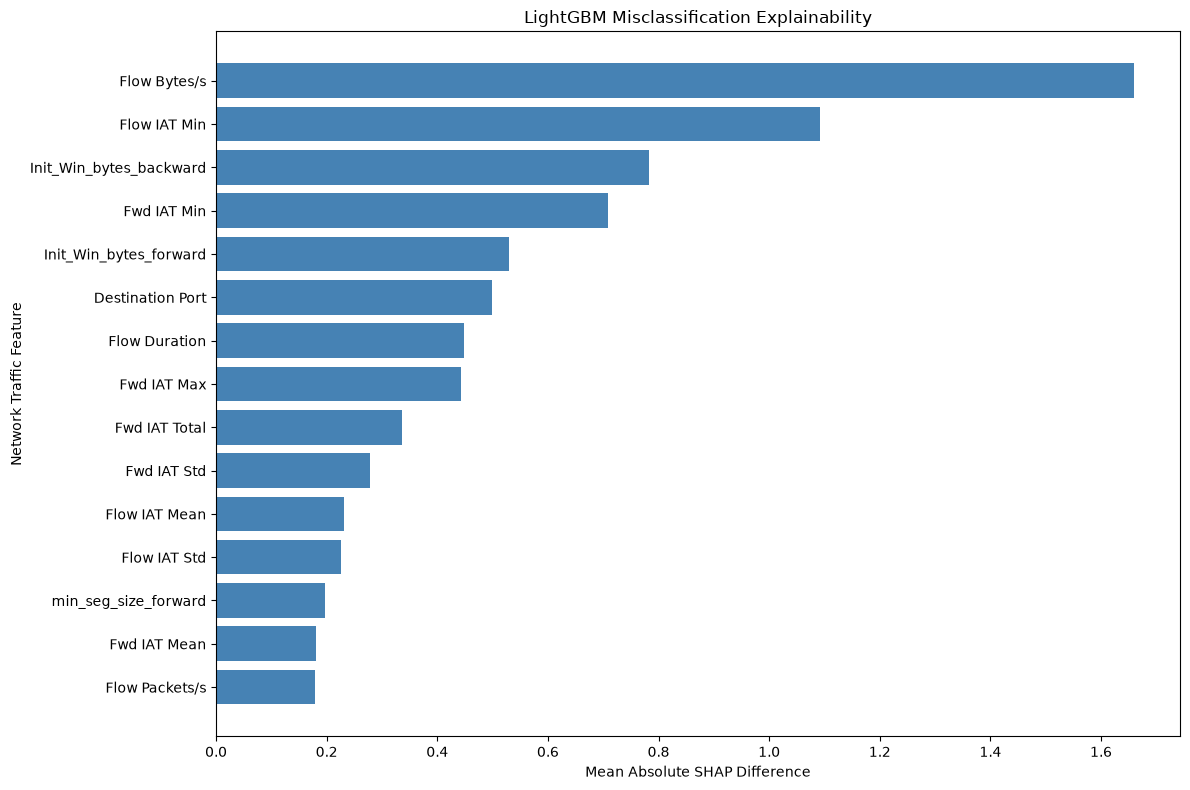

,Verification_Check,Status
0,Misclassified records identified,PASS
1,Complete misclassification coverage,PASS
2,Actual and predicted classes differ,PASS
3,Complete feature contributions,PASS
4,All SHAP differences finite,PASS
5,Score margin reconstruction verified,PASS
6,All 69 features ranked,PASS
7,Pattern counts consistent,PASS
8,Results files saved,PASS
9,Figure saved,PASS



MISCLASSIFICATION EXPLAINABILITY SUMMARY
-----------------------------------------------------------------
Sample records: 2343
Misclassified records analysed: 115
Feature contributions analysed: 7935
Misclassification patterns: 6
Most influential feature: Flow Bytes/s
Results files saved: 4
Figures saved: 1
Total checks: 10
Passed checks: 10
Execution time: 1.91 seconds
-----------------------------------------------------------------
Misclassification explainability: PASS
Misclassification analysis completed successfully.


In [15]:
# Step 15: Misclassification explainability analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from time import perf_counter

assert local_explanation_passed

start_time = perf_counter()

print("MISCLASSIFICATION EXPLAINABILITY ANALYSIS")
print("-" * 65)


# Identify the verified sample targets

mis_true_labels = np.asarray(y_xai_sample)

assert mis_true_labels.shape == (2343,)

assert len(np.unique(mis_true_labels)) == 15

print("Target variable: y_xai_sample")
print("Target dimensions:", mis_true_labels.shape)
print("Unique target classes:", len(np.unique(mis_true_labels)))
print("Target identification: PASS")

class_names = np.asarray(xai_class_names)
model_classes = np.asarray(evaluation_model.classes_) if (
    "evaluation_model" in globals()
) else np.arange(len(class_names))

# Convert actual targets to class positions

if np.isin(mis_true_labels, class_names).all():

    class_mapping = {
        name: i for i, name in enumerate(class_names)
    }

else:

    class_mapping = {
        label: i for i, label in enumerate(model_classes)
    }

mis_true_positions = np.array([
    class_mapping[label]
    for label in mis_true_labels
])

mis_pred_positions = np.argmax(
    xai_raw_scores,
    axis=1
)

assert len(mis_true_positions) == 2343
assert len(mis_pred_positions) == 2343

# Identify incorrectly classified samples

misclassified_positions = np.flatnonzero(
    mis_true_positions != mis_pred_positions
)

print(
    "Total SHAP sample records:",
    len(mis_true_positions)
)

print(
    "Misclassified sample records:",
    len(misclassified_positions)
)

assert len(misclassified_positions) > 0

# Analyse all sampled misclassifications

misclassification_records = []
misclassification_summary = []

for position in misclassified_positions:

    actual_index = int(
        mis_true_positions[position]
    )

    predicted_index = int(
        mis_pred_positions[position]
    )

    actual_shap = xai_shap_values[
        position, :, actual_index
    ]

    predicted_shap = xai_shap_values[
        position, :, predicted_index
    ]

    contribution_difference = (
        predicted_shap - actual_shap
    )

    ranked_features = np.argsort(
        -np.abs(contribution_difference)
    )

    actual_score = float(
        xai_raw_scores[position, actual_index]
    )

    predicted_score = float(
        xai_raw_scores[position, predicted_index]
    )

    baseline_difference = float(
        local_baselines[predicted_index]
        - local_baselines[actual_index]
    )

    reconstructed_margin = float(
        baseline_difference
        + contribution_difference.sum()
    )

    score_margin = predicted_score - actual_score

    misclassification_summary.append({

        "Sample_Position": int(position),

        "Actual_Class": class_names[actual_index],

        "Predicted_Class": class_names[predicted_index],

        "Actual_Raw_Score": actual_score,

        "Predicted_Raw_Score": predicted_score,

        "Score_Margin": score_margin,

        "Baseline_Difference": baseline_difference,

        "Reconstructed_Margin": reconstructed_margin,

        "Reconstruction_Error": abs(
            score_margin - reconstructed_margin
        ),

        "Most_Influential_Feature":
            global_feature_names[ranked_features[0]]

    })

    for rank, feature_index in enumerate(
        ranked_features,
        start=1
    ):

        misclassification_records.append({

            "Sample_Position": int(position),

            "Actual_Class": class_names[actual_index],

            "Predicted_Class": class_names[predicted_index],

            "Rank": rank,

            "Feature":
                global_feature_names[feature_index],

            "Actual_Class_SHAP":
                float(actual_shap[feature_index]),

            "Predicted_Class_SHAP":
                float(predicted_shap[feature_index]),

            "SHAP_Difference":
                float(
                    contribution_difference[feature_index]
                ),

            "Absolute_Difference":
                float(
                    abs(
                        contribution_difference[feature_index]
                    )
                )

        })

# Construct analysis tables

misclassification_df = pd.DataFrame(
    misclassification_records
)

misclassification_summary_df = pd.DataFrame(
    misclassification_summary
)

# Summarise misclassification patterns

misclassification_patterns_df = (
    misclassification_summary_df
    .groupby(
        ["Actual_Class", "Predicted_Class"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

# Aggregate influential features

misclassification_importance_df = (
    misclassification_df
    .groupby("Feature")["Absolute_Difference"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

print("\nMISCLASSIFICATION PATTERNS")
display(misclassification_patterns_df.head(15))

print("\nTOP 15 MISCLASSIFICATION FEATURES")
display(misclassification_importance_df.head(15))

# Generate feature importance figure

top_mis_features = (
    misclassification_importance_df
    .head(15)
    .sort_values("Absolute_Difference")
)

plt.figure(figsize=(12, 8))

plt.barh(
    top_mis_features["Feature"],
    top_mis_features["Absolute_Difference"],
    color="steelblue"
)

plt.xlabel("Mean Absolute SHAP Difference")
plt.ylabel("Network Traffic Feature")

plt.title(
    "LightGBM Misclassification Explainability"
)

plt.tight_layout()

misclassification_figure_path = (
    figures_dir
    / "05_misclassification_shap_importance.png"
)

plt.savefig(
    misclassification_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Save research artifacts

misclassification_outputs = {

    "05_misclassification_shap_details.csv":
        misclassification_df,

    "05_misclassification_shap_summary.csv":
        misclassification_summary_df,

    "05_misclassification_shap_patterns.csv":
        misclassification_patterns_df,

    "05_misclassification_shap_importance.csv":
        misclassification_importance_df

}

for filename, dataframe in (
    misclassification_outputs.items()
):

    dataframe.to_csv(
        results_dir / filename,
        index=False
    )

# Verification checks

misclassification_checks = {

    "Misclassified records identified":
        len(misclassified_positions) > 0,

    "Complete misclassification coverage":
        len(misclassification_summary_df)
        == len(misclassified_positions),

    "Actual and predicted classes differ":
        bool(
            (
                misclassification_summary_df["Actual_Class"]
                !=
                misclassification_summary_df["Predicted_Class"]
            ).all()
        ),

    "Complete feature contributions":
        len(misclassification_df)
        == len(misclassified_positions) * 69,

    "All SHAP differences finite":
        bool(
            np.isfinite(
                misclassification_df["SHAP_Difference"]
            ).all()
        ),

    "Score margin reconstruction verified":
        bool(
            (
                misclassification_summary_df[
                    "Reconstruction_Error"
                ] <= 2 * additivity_tolerance
            ).all()
        ),

    "All 69 features ranked":
        len(misclassification_importance_df) == 69,

    "Pattern counts consistent":
        misclassification_patterns_df["Count"].sum()
        == len(misclassified_positions),

    "Results files saved":
        all(
            (results_dir / filename).exists()
            for filename in misclassification_outputs
        ),

    "Figure saved":
        misclassification_figure_path.exists()

}

misclassification_checks_df = pd.DataFrame([

    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }

    for name, passed in misclassification_checks.items()

])

display(misclassification_checks_df)

misclassification_explainability_passed = bool(
    all(misclassification_checks.values())
)

print("\nMISCLASSIFICATION EXPLAINABILITY SUMMARY")
print("-" * 65)

print("Sample records:", len(mis_true_positions))

print(
    "Misclassified records analysed:",
    len(misclassified_positions)
)

print(
    "Feature contributions analysed:",
    len(misclassification_df)
)

print(
    "Misclassification patterns:",
    len(misclassification_patterns_df)
)

print(
    "Most influential feature:",
    misclassification_importance_df.iloc[0]["Feature"]
)

print("Results files saved: 4")
print("Figures saved: 1")

print("Total checks:", len(misclassification_checks))

print(
    "Passed checks:",
    sum(misclassification_checks.values())
)

print(
    f"Execution time: "
    f"{perf_counter() - start_time:.2f} seconds"
)

assert misclassification_explainability_passed

print("-" * 65)
print("Misclassification explainability: PASS")
print("Misclassification analysis completed successfully.")

In [16]:
from pathlib import Path
import pandas as pd
import json

project_root = Path(r"C:\Users\pc\XAI-Intrusion-Detection")

print("EXPLAINABLE AI ARTIFACT VERIFICATION")
print("-" * 65)

xai_files = sorted(
    p for p in project_root.rglob("05_*")
    if p.is_file()
    and p.suffix.lower() in {
        ".csv", ".json", ".npy", ".npz",
        ".png", ".pdf", ".joblib", ".parquet"
    }
    and ".ipynb_checkpoints" not in p.parts
)

artifact_records = []

for path in xai_files:
    artifact_records.append({
        "File": str(path.relative_to(project_root)),
        "Size_KB": round(path.stat().st_size / 1024, 2),
        "Status": "PASS" if path.stat().st_size > 0 else "FAIL"
    })

artifact_df = pd.DataFrame(artifact_records)

assert not artifact_df.empty, "No XAI artifacts found."

display(artifact_df)

assert artifact_df["Status"].eq("PASS").all(), \
    "Empty artifact detected."

print("-" * 65)
print("Total artifacts discovered:", len(artifact_df))
print("Non-empty artifacts:", artifact_df["Status"].eq("PASS").sum())
print("Artifact verification: PASS")

manifest_path = (
    project_root / "results" / "05_artifact_manifest.csv"
)

artifact_df.to_csv(manifest_path, index=False)

print("Artifact manifest saved:", manifest_path.name)
print("Explainable AI artifact inventory completed.")

EXPLAINABLE AI ARTIFACT VERIFICATION
-----------------------------------------------------------------


,File,Size_KB,Status
0,figures\05_class_specific_shap_heatmap.png,398.86,PASS
1,figures\05_global_shap_feature_importance.png,225.99,PASS
2,figures\05_local_shap_case_01.png,245.89,PASS
3,figures\05_local_shap_case_02.png,256.22,PASS
4,figures\05_local_shap_case_03.png,243.29,PASS
5,figures\05_local_shap_case_04.png,249.24,PASS
6,figures\05_local_shap_case_05.png,247.56,PASS
7,figures\05_misclassification_shap_importance.png,169.83,PASS
8,results\05_class_shap_feature_rankings.csv,67.01,PASS
9,results\05_class_shap_importance_matrix.csv,18.51,PASS


-----------------------------------------------------------------
Total artifacts discovered: 18
Non-empty artifacts: 18
Artifact verification: PASS
Artifact manifest saved: 05_artifact_manifest.csv
Explainable AI artifact inventory completed.


In [17]:
# RETRIEVE ORIGINAL FEATURE RECONSTRUCTION CODE

for i, code in enumerate(In[:-1]):
    if "SHAP feature reconstruction completed" in code:
        print("Cell number:", i)
        print("-" * 65)
        print(code)
        print("-" * 65)

Cell number: 6
-----------------------------------------------------------------
# SHAP sample feature reconstruction

from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import joblib

start_time = perf_counter()

print("SHAP FEATURE RECONSTRUCTION")
print("-" * 65)

project_root = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

results_dir = project_root / "results"

feature_names = list(joblib.load(
    results_dir / "03_development_feature_names.joblib"
))

scaler = joblib.load(
    results_dir / "03_development_scaler.joblib"
)

replacement_values = joblib.load(
    results_dir / "03_development_replacement_values.joblib"
)

parquet_file = pq.ParquetFile(
    project_root / "processed_data"
    / "CICIDS2017_cleaned.parquet"
)

assert len(feature_names) == 69
assert list(scaler.feature_names_in_) == feature_names
assert np.all(scaler.n_samples_seen_ == 1613310)

total_records = parquet_file.metadata.num_ro